# 00 · Data audit & KPI export

**Goal:** understand the Cottonil data, check it is trustworthy, and export the small KPI tables that power the
*Executive Overview* tab of the app.

**What this notebook does**
1. Loads every table through a schema validator (fails early if a real file is missing a column).
2. Runs **data-quality checks** (identities such as `net + tax = paid`, orphan keys, anonymous share, marketing attribution sanity).
3. Computes headline KPIs and charts.
4. Exports `kpi_*` / `dim_*` serving tables to `artifacts/serving/`.

> Run order for the project: `00 → 01 → 02 → 03 → 04 → 05 → 06 → 07` (02 needs 01's forecasts).

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))                       # lets the notebook import the `cottonil` package
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cottonil import config as cfg
from cottonil.data_io import load_table, load_sales_lines, load_product_master, week_start, quick_profile
from cottonil.plotting import setup, NAVY, TEAL, ORANGE, RED, PALETTE
setup()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

DATA_DIR = cfg.find_data_dir()
SOURCE = cfg.data_source(DATA_DIR)
print(f"Data folder : {DATA_DIR}")
print(f"Data source : {SOURCE.upper()}" + ("   <-- synthetic test data; retrain on real data before trusting any number" if SOURCE == "synthetic" else ""))

Data folder : D:\HVIA Internship\task 2\cottonil-ai\COTTONIL_Data
Data source : REAL


## 1 · Load & profile every table

In [2]:
names = ["branches", "customers", "products_catalog", "sku_variants", "sales_orders", "sales_order_items",
         "sales_returns", "monthly_stock", "purchase_orders", "purchase_order_items", "suppliers",
         "warehouses", "marketing_campaigns", "inventory_transfers"]
T = {n: load_table(n) for n in names}          # raises a clear error if a column is missing
summary = pd.DataFrame({n: {"rows": len(d), "columns": d.shape[1], "null cells": int(d.isna().sum().sum()),
                            "duplicate rows": int(d.duplicated().sum())} for n, d in T.items()}).T
summary

,rows,columns,null cells,duplicate rows
branches,80,6,0,0
customers,85000,5,0,0
products_catalog,139,5,0,0
sku_variants,695,5,0,0
sales_orders,540000,13,102961,0
sales_order_items,1138536,13,0,0
sales_returns,28500,9,0,0
monthly_stock,142784,7,0,0
purchase_orders,41500,9,0,0
purchase_order_items,103334,7,0,0


In [3]:
orders, items = T["sales_orders"], T["sales_order_items"]
print("Date range :", orders.order_date.min().date(), "->", orders.order_date.max().date())
print("Orders     :", f"{len(orders):,}", "| lines:", f"{len(items):,}", "| customers:", f"{len(T['customers']):,}")
quick_profile(orders, "sales_orders")

Date range : 2018-10-19 -> 2026-10-18
Orders     : 540,000 | lines: 1,138,536 | customers: 85,000


,dtype,nulls,null_%,unique
sales_orders,,,,
sales_order_id,object,0,0.00,540000
order_date,datetime64[ns],0,0.00,2922
branch_id,object,0,0.00,80
customer_id,object,102961,19.07,74660
sales_channel,object,0,0.00,3
payment_method,object,0,0.00,5
items_count,int64,0,0.00,5
gross_EGP,float64,0,0.00,248734
discount_EGP,float64,0,0.00,47656


## 2 · Data-quality checks
Each check returns `PASS` or `WARN`. A WARN is not an error in itself — it is something a human should look at
before trusting downstream numbers.

In [4]:
checks = []
def chk(name, ok, detail):
    checks.append({"check": name, "status": "PASS" if ok else "WARN", "detail": detail})

# --- keys & identities ------------------------------------------------------
chk("sales_order_id unique", orders.sales_order_id.is_unique, f"{orders.sales_order_id.duplicated().sum()} duplicates")
chk("sales_line_id unique", items.sales_line_id.is_unique, f"{items.sales_line_id.duplicated().sum()} duplicates")
orphan_lines = (~items.sales_order_id.isin(orders.sales_order_id)).sum()
chk("every line belongs to an order", orphan_lines == 0, f"{orphan_lines} orphan lines")
lines_per_order = items.groupby("sales_order_id").size().reindex(orders.sales_order_id).fillna(0).values
bad = (lines_per_order != orders.items_count.values).sum()
chk("items_count == number of lines", bad == 0, f"{bad} orders differ")
d1 = (orders.net_before_tax_EGP - (orders.gross_EGP - orders.discount_EGP)).abs()
chk("net = gross - discount", (d1 > .05).mean() < .001, f"{(d1 > .05).sum()} rows off by >0.05")
d2 = (orders.paid_total_EGP - (orders.net_before_tax_EGP + orders.tax_EGP)).abs()
chk("paid = net + tax", (d2 > .05).mean() < .001, f"{(d2 > .05).sum()} rows off by >0.05")
d3 = (items.margin_EGP - (items.net_line_EGP - items.quantity * items.unit_cost_EGP)).abs()
chk("margin = net - qty*cost", (d3 > .05).mean() < .001, f"{(d3 > .05).sum()} rows off by >0.05")
ret = T["sales_returns"]
chk("every return points to a real line", ret.sales_line_id.isin(items.sales_line_id).all(),
    f"{(~ret.sales_line_id.isin(items.sales_line_id)).sum()} orphan returns")
chk("no non-positive prices/quantities", ((items.quantity <= 0) | (items.unit_price_EGP <= 0)).sum() == 0, "")
_r = ret.merge(orders[["sales_order_id", "order_date"]], on="sales_order_id", how="left")
n_before = int((_r.return_date < _r.order_date).sum())
chk("returns happen on/after the sale date", n_before == 0, f"{n_before} returns dated before their order")

# --- business sanity --------------------------------------------------------
anon = orders.customer_id.isna().mean()
chk("anonymous orders (customer_id null)", anon < .05, f"{anon:.1%} of orders have no customer  -> CRM blind spot")
mk = T["marketing_campaigns"]
ratio = mk.orders_attributed.sum() / len(orders)
chk("marketing attributed orders <= ledger orders", ratio <= 1.5,
    f"campaigns claim {mk.orders_attributed.sum():,} orders vs {len(orders):,} in the sales ledger ({ratio:.0f}x)  -> use channel *efficiency ranking*, not absolute counts")
po = T["purchase_orders"]
chk("partial-receipt PO rate", (po.po_status == 'Partial receipt').mean() < .15, f"{(po.po_status == 'Partial receipt').mean():.1%} of POs arrive partially")
ret_rate = len(ret) / len(items)
chk("line-level return rate", ret_rate < .10, f"{ret_rate:.2%} of sales lines have a return record")
dq = pd.DataFrame(checks)
dq

,check,status,detail
0,sales_order_id unique,PASS,0 duplicates
1,sales_line_id unique,PASS,0 duplicates
2,every line belongs to an order,PASS,0 orphan lines
3,items_count == number of lines,PASS,0 orders differ
4,net = gross - discount,PASS,0 rows off by >0.05
5,paid = net + tax,PASS,0 rows off by >0.05
6,margin = net - qty*cost,PASS,0 rows off by >0.05
7,every return points to a real line,PASS,0 orphan returns
8,no non-positive prices/quantities,PASS,
9,returns happen on/after the sale date,PASS,0 returns dated before their order


**How to read the WARNs.** Anonymous orders and the marketing attribution gap are *business findings*, not bugs —
they are exactly what the later notebooks (churn / entity resolution, marketing optimizer) deal with. The marketing one
matters: platform-reported attributed orders are usually inflated, so notebook 07 only trusts **relative** channel efficiency.

## 3 · Headline KPIs

In [5]:
rev = orders.net_before_tax_EGP.sum()
gm = items.margin_EGP.sum()
units = items.quantity.sum()
kpi = {
    "orders": int(len(orders)), "lines": int(len(items)), "units": int(units),
    "revenue_egp": float(rev), "gross_margin_egp": float(gm), "gross_margin_pct": float(gm / items.net_line_EGP.sum()),
    "aov_egp": float(rev / len(orders)), "items_per_order": float(orders.items_count.mean()),
    "single_item_share": float((orders.items_count == 1).mean()),
    "anonymous_share": float(anon), "customers": int(len(T["customers"])), "branches": int(len(T["branches"])),
    "return_rate_orders": float(ret.sales_order_id.nunique() / len(orders)), "refunds_egp": float(ret.refund_amount_EGP.sum()),
    "first_date": str(orders.order_date.min().date()), "last_date": str(orders.order_date.max().date()),
}
pd.Series(kpi).to_frame("value")

,value
orders,540000
lines,1138536
units,3398655
revenue_egp,841274176.32
gross_margin_egp,322558299.5
gross_margin_pct,0.383416
aov_egp,1557.915141
items_per_order,2.1084
single_item_share,0.320387
anonymous_share,0.190669


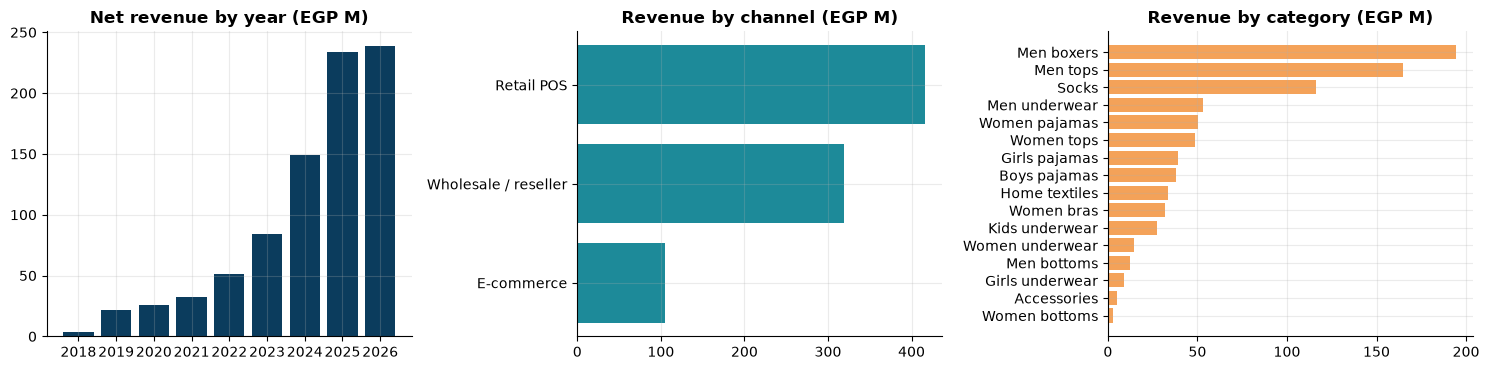

,rev,units
category,,
Men boxers,194199147.0,381819
Men tops,164524154.0,442948
Socks,116179055.0,911138
Men underwear,53063019.0,189180
Women pajamas,50215875.0,78090
Women tops,48536514.0,339951


In [6]:
orders["ym"] = orders.order_date.dt.to_period("M").astype(str)
orders["year"] = orders.order_date.dt.year
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
yr = orders.groupby("year").net_before_tax_EGP.sum() / 1e6
ax[0].bar(yr.index.astype(str), yr.values, color=NAVY); ax[0].set_title("Net revenue by year (EGP M)")
ch = orders.groupby("sales_channel").net_before_tax_EGP.sum().sort_values()
ax[1].barh(ch.index, ch.values / 1e6, color=TEAL); ax[1].set_title("Revenue by channel (EGP M)")
cat = load_sales_lines().groupby("category", observed=True).agg(rev=("net_line_EGP", "sum"), units=("quantity", "sum")).sort_values("rev")
ax[2].barh(cat.index.astype(str), cat.rev / 1e6, color=ORANGE); ax[2].set_title("Revenue by category (EGP M)")
plt.tight_layout(); plt.show()
cat.sort_values("rev", ascending=False).head(6).round(0)

## 4 · Export serving tables for the app
These are *aggregated* tables (a few thousand rows), so the deployed app never needs the 1M-row raw data.

In [7]:
lines = load_sales_lines()
lines["ym"] = lines.order_date.dt.to_period("M").astype(str)

kpi_monthly = (orders.groupby(["ym", "sales_channel"], observed=True)
               .agg(orders=("sales_order_id", "size"), revenue=("net_before_tax_EGP", "sum"), items=("items_count", "sum"))
               .reset_index())
kpi_cat_month = (lines.groupby(["ym", "category"], observed=True)
                 .agg(revenue=("net_line_EGP", "sum"), units=("quantity", "sum"), margin=("margin_EGP", "sum"))
                 .reset_index())
kpi_cat_month["category"] = kpi_cat_month["category"].astype(str)

br = T["branches"]
last12 = orders.order_date.max() - pd.Timedelta(days=365)
kpi_branch = (orders.groupby("branch_id").agg(orders=("sales_order_id", "size"), revenue=("net_before_tax_EGP", "sum")).reset_index()
              .merge(orders[orders.order_date > last12].groupby("branch_id").net_before_tax_EGP.sum().rename("revenue_12m").reset_index(), how="left")
              .merge(br[["branch_id", "branch_name_ar", "governorate_ar", "retail_location_type"]], on="branch_id", how="left"))

ret_x = ret.merge(items[["sales_line_id", "sku_id"]].merge(load_product_master()[["sku_id", "category", "size"]], on="sku_id"),
                  on=["sales_line_id", "sku_id"], how="left")
kpi_returns = (ret_x.groupby(["category", "size", "reason"], dropna=False)
               .agg(returns=("return_id", "size"), refund=("refund_amount_EGP", "sum")).reset_index())

recent = lines[lines.order_date > last12]
prod_stats = recent.groupby("product_id", observed=True).agg(units_12m=("quantity", "sum"), revenue_12m=("net_line_EGP", "sum"),
                                                              margin_12m=("margin_EGP", "sum")).reset_index()
dim_products = (T["products_catalog"][["product_id", "product_name_ar", "category_en", "audience", "listed_price_EGP"]]
                .merge(prod_stats, on="product_id", how="left").fillna({"units_12m": 0, "revenue_12m": 0, "margin_12m": 0}))
dim_products["margin_per_unit"] = (dim_products.margin_12m / dim_products.units_12m.replace(0, np.nan)).fillna(dim_products.listed_price_EGP * .38)
dim_products["avg_price_12m"] = (dim_products.revenue_12m / dim_products.units_12m.replace(0, np.nan)).fillna(dim_products.listed_price_EGP)
dim_branches = br[["branch_id", "branch_name_ar", "governorate_ar", "city_ar", "retail_location_type"]]

for name, df in {"kpi_monthly": kpi_monthly, "kpi_category_month": kpi_cat_month, "kpi_branch": kpi_branch,
                 "kpi_returns": kpi_returns, "dim_products": dim_products, "dim_branches": dim_branches}.items():
    p = cfg.save_serving(name, df)
    print(f"{name:20s} {len(df):>7,} rows  {p.stat().st_size / 1e3:7.0f} KB")
cfg.save_metrics("00_data_audit", {"kpis": kpi, "data_quality": dq.to_dict("records"), "n_pass": int((dq.status == 'PASS').sum()),
                                   "n_warn": int((dq.status == 'WARN').sum())}, DATA_DIR)

kpi_monthly              291 rows        4 KB
kpi_category_month     1,552 rows       25 KB
kpi_branch                80 rows        3 KB
kpi_returns              410 rows        4 KB
dim_products             139 rows        7 KB
dim_branches              80 rows        2 KB


WindowsPath('D:/HVIA Internship/task 2/cottonil-ai/artifacts/metrics/00_data_audit.json')

## Takeaways
* The ledger identities hold, so revenue / margin numbers can be trusted as computed.
* **19% of orders are anonymous** → notebook 03 (customer intelligence) scores only identified customers and recommends a loyalty-capture action.
* **Marketing-attributed orders are far larger than the sales ledger** → notebook 07 uses relative efficiency only.
* Next: `01_demand_forecasting.ipynb`.